In [1]:

from pathlib import Path
import urllib.request
import shutil
import os

CURRENT_DIR = Path.cwd().resolve()
PROJECT_DIR = next(
    (folder for folder in [CURRENT_DIR, *CURRENT_DIR.parents]
     if (folder / "notebooks").is_dir() and (folder / "src").is_dir()),
    CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
)

DATA_DIR = PROJECT_DIR / "data" / "store_item_demand"
DATA_DIR.mkdir(parents=True, exist_ok=True)
DATASET_PATH = DATA_DIR / "train.csv"
DOWNLOAD_URL = "https://raw.githubusercontent.com/DharitShah13/Kaggle-Store-Item-Demand-Forecasting-Challenge/master/train.csv"

if DATASET_PATH.is_file() and DATASET_PATH.stat().st_size > 1_000_000:
    print("Store Item Demand dataset is already available.")
else:
    temporary_path = DATA_DIR / "train.csv.download"
    request = urllib.request.Request(
        DOWNLOAD_URL,
        headers={"User-Agent": "Mozilla/5.0 RetailMind-AI-Day10"}
    )
    try:
        print("Downloading Store Item Demand Forecasting dataset...")
        with urllib.request.urlopen(request, timeout=90) as response:
            with temporary_path.open("wb") as output_file:
                shutil.copyfileobj(response, output_file)
        if temporary_path.stat().st_size < 1_000_000:
            raise ValueError("The downloaded file is smaller than expected.")
        os.replace(temporary_path, DATASET_PATH)
        print("Dataset downloaded successfully.")
    except Exception as error:
        if temporary_path.exists():
            temporary_path.unlink()
        raise RuntimeError(
            "Automatic download failed. Download train.csv from "
            "https://www.kaggle.com/competitions/demand-forecasting-kernels-only/data "
            f"and save it as {DATASET_PATH}. Original error: {error}"
        ) from error

print("Project folder:", PROJECT_DIR)
print("Dataset:", DATASET_PATH)


Store Item Demand dataset is already available.
Project folder: C:\Users\rupam\OneDrive\Desktop\Retail_Mind
Dataset: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\data\store_item_demand\train.csv


In [2]:

import json
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

SEED = 42
STORE_ID = 1
ITEM_ID = 1
LOOK_BACK = 30
FORECAST_HORIZON = 14
BATCH_SIZE = 32
EPOCHS = 30

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

MODEL_DIR = PROJECT_DIR / "models" / "forecasting"
REPORT_DIR = PROJECT_DIR / "reports" / "day10_seq2seq_attention"
SRC_DIR = PROJECT_DIR / "src"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
SRC_DIR.mkdir(parents=True, exist_ok=True)

DAY9_MODEL_PATH = MODEL_DIR / "retailmind_lstm_demand.keras"
DAY9_METADATA_PATH = MODEL_DIR / "retailmind_lstm_metadata.json"
MODEL_PATH = MODEL_DIR / "retailmind_seq2seq_attention.keras"
METADATA_PATH = MODEL_DIR / "retailmind_seq2seq_metadata.json"

print("TensorFlow:", tf.__version__)
print("Project folder:", PROJECT_DIR)
print("Store:", STORE_ID, "Item:", ITEM_ID)
print("History window:", LOOK_BACK, "days")
print("Forecast horizon:", FORECAST_HORIZON, "days")


TensorFlow: 2.22.0-rc0
Project folder: C:\Users\rupam\OneDrive\Desktop\Retail_Mind
Store: 1 Item: 1
History window: 30 days
Forecast horizon: 14 days


In [3]:

sales_data = pd.read_csv(DATASET_PATH, parse_dates=["date"])
sales_data.columns = sales_data.columns.str.strip().str.lower()

required_columns = {"date", "store", "item", "sales"}
missing_columns = required_columns.difference(sales_data.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")

sales_data = sales_data.dropna(subset=["date", "store", "item", "sales"]).copy()
for column in ["store", "item", "sales"]:
    sales_data[column] = pd.to_numeric(sales_data[column], errors="coerce")
sales_data = sales_data.dropna(subset=["store", "item", "sales"])
sales_data["store"] = sales_data["store"].astype(int)
sales_data["item"] = sales_data["item"].astype(int)

selected_sales = sales_data[
    (sales_data["store"] == STORE_ID) &
    (sales_data["item"] == ITEM_ID)
].copy()

if selected_sales.empty:
    raise ValueError(f"No sales records found for Store {STORE_ID}, Item {ITEM_ID}.")

selected_sales = selected_sales.sort_values("date").set_index("date")
daily_sales = selected_sales["sales"].resample("D").sum().asfreq("D", fill_value=0)
daily_sales = daily_sales.astype("float32")
daily_sales.name = "sales"

if len(daily_sales) <= LOOK_BACK + FORECAST_HORIZON * 3:
    raise ValueError("The selected time series is too short for the configured windows.")

print("Dataset rows:", len(sales_data))
print("Selected series records:", len(daily_sales))
print("Date range:", daily_sales.index.min().date(), "to", daily_sales.index.max().date())
print(daily_sales.describe())


Dataset rows: 913000
Selected series records: 1826
Date range: 2013-01-01 to 2017-12-31
count    1826.000000
mean       19.971523
std         6.741022
min         4.000000
25%        15.000000
50%        19.000000
75%        24.000000
max        50.000000
Name: sales, dtype: float64


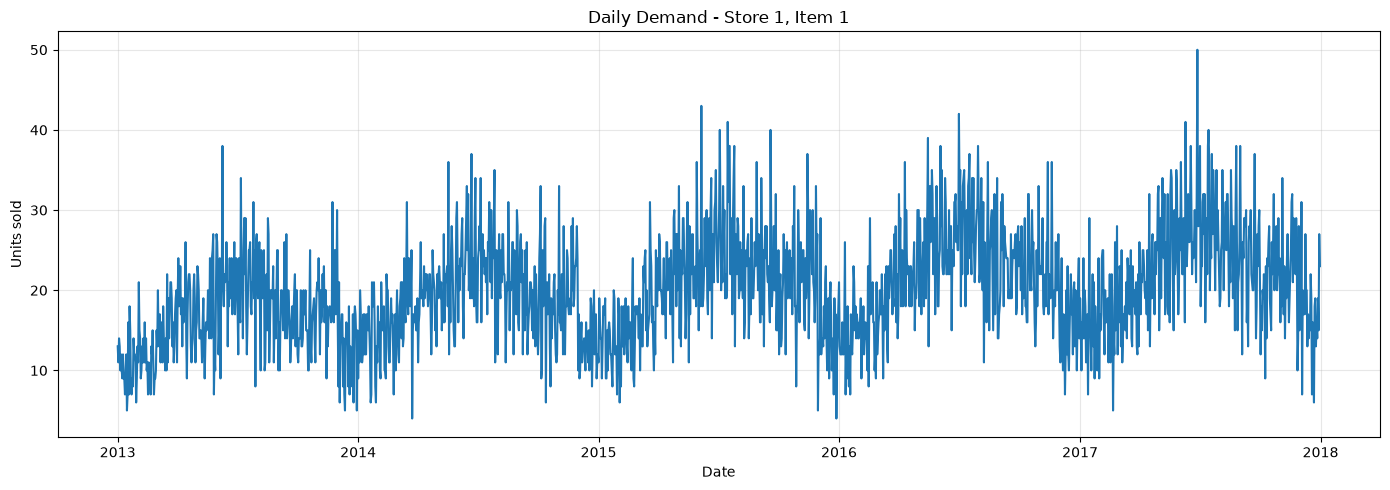

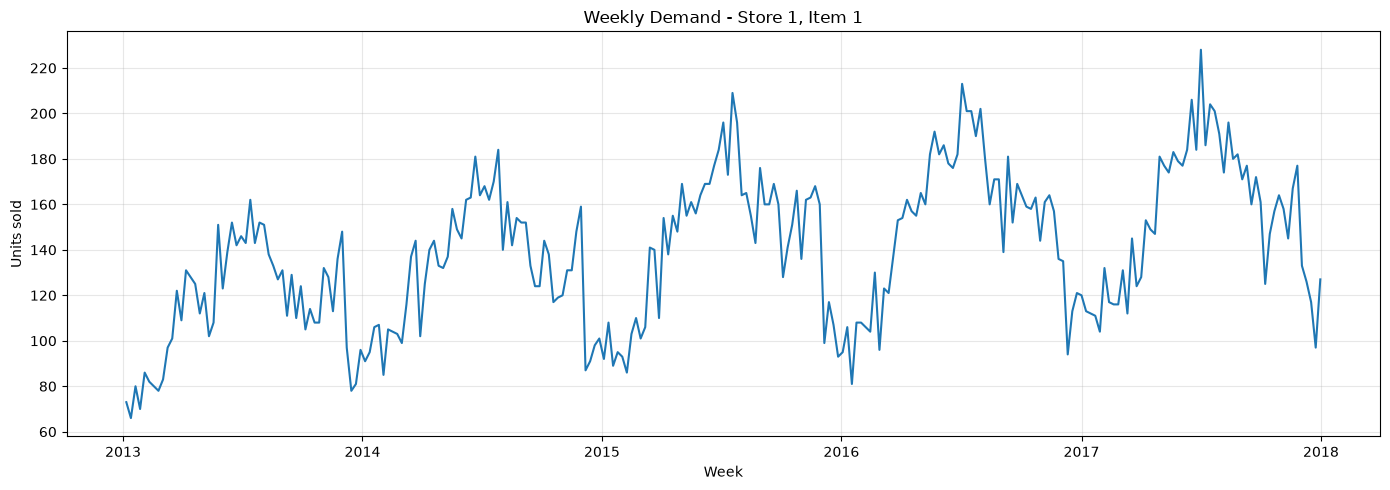

In [4]:

plt.figure(figsize=(14, 5))
plt.plot(daily_sales.index, daily_sales.values)
plt.title(f"Daily Demand - Store {STORE_ID}, Item {ITEM_ID}")
plt.xlabel("Date")
plt.ylabel("Units sold")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

weekly_sales = daily_sales.resample("W").sum()
plt.figure(figsize=(14, 5))
plt.plot(weekly_sales.index, weekly_sales.values)
plt.title(f"Weekly Demand - Store {STORE_ID}, Item {ITEM_ID}")
plt.xlabel("Week")
plt.ylabel("Units sold")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [5]:

sales_values = daily_sales.to_numpy(dtype=np.float32)
number_of_observations = len(sales_values)

train_end = int(number_of_observations * 0.70)
validation_end = int(number_of_observations * 0.85)

scale_min = float(sales_values[:train_end].min())
scale_max = float(sales_values[:train_end].max())
scale_range = scale_max - scale_min
if scale_range == 0:
    scale_range = 1.0

scaled_sales = ((sales_values - scale_min) / scale_range).astype(np.float32)


def create_seq2seq_windows(values, first_origin, last_origin, look_back, horizon):
    encoder_windows = []
    decoder_windows = []
    target_windows = []
    origins = []

    for origin in range(first_origin, last_origin):
        history_window = values[origin - look_back:origin]
        target_window = values[origin:origin + horizon]
        decoder_input = np.concatenate([history_window[-1:], target_window[:-1]])

        if len(history_window) == look_back and len(target_window) == horizon:
            encoder_windows.append(history_window.reshape(look_back, 1))
            decoder_windows.append(decoder_input.reshape(horizon, 1))
            target_windows.append(target_window.reshape(horizon, 1))
            origins.append(origin)

    return (
        np.asarray(encoder_windows, dtype=np.float32),
        np.asarray(decoder_windows, dtype=np.float32),
        np.asarray(target_windows, dtype=np.float32),
        np.asarray(origins, dtype=int)
    )


train_last_origin = train_end - FORECAST_HORIZON + 1
validation_last_origin = validation_end - FORECAST_HORIZON + 1
test_last_origin = number_of_observations - FORECAST_HORIZON + 1

x_train_encoder, x_train_decoder, y_train, train_origins = create_seq2seq_windows(
    scaled_sales, LOOK_BACK, train_last_origin, LOOK_BACK, FORECAST_HORIZON
)
x_validation_encoder, x_validation_decoder, y_validation, validation_origins = create_seq2seq_windows(
    scaled_sales, train_end, validation_last_origin, LOOK_BACK, FORECAST_HORIZON
)
x_test_encoder, x_test_decoder, y_test, test_origins = create_seq2seq_windows(
    scaled_sales, validation_end, test_last_origin, LOOK_BACK, FORECAST_HORIZON
)

if not len(x_train_encoder) or not len(x_validation_encoder) or not len(x_test_encoder):
    raise ValueError("Not enough sequence windows. Check the look-back and forecast horizon.")

print("Training:", x_train_encoder.shape, x_train_decoder.shape, y_train.shape)
print("Validation:", x_validation_encoder.shape, x_validation_decoder.shape, y_validation.shape)
print("Testing:", x_test_encoder.shape, x_test_decoder.shape, y_test.shape)
print("Training ends:", daily_sales.index[train_end - 1].date())
print("Validation ends:", daily_sales.index[validation_end - 1].date())


Training: (1235, 30, 1) (1235, 14, 1) (1235, 14, 1)
Validation: (261, 30, 1) (261, 14, 1) (261, 14, 1)
Testing: (261, 30, 1) (261, 14, 1) (261, 14, 1)
Training ends: 2016-07-01
Validation ends: 2017-04-01


In [6]:

encoder_inputs = tf.keras.Input(shape=(LOOK_BACK, 1), name="history_input")
decoder_inputs = tf.keras.Input(shape=(FORECAST_HORIZON, 1), name="decoder_input")

encoder_sequence, encoder_state_h, encoder_state_c = tf.keras.layers.LSTM(
    64, return_sequences=True, return_state=True, name="encoder_lstm"
)(encoder_inputs)

decoder_sequence = tf.keras.layers.LSTM(
    64, return_sequences=True, name="decoder_lstm"
)(
    decoder_inputs,
    initial_state=[encoder_state_h, encoder_state_c]
)

attention_layer = tf.keras.layers.Attention(name="temporal_attention")
context_sequence, attention_scores = attention_layer(
    [decoder_sequence, encoder_sequence],
    return_attention_scores=True
)

combined_sequence = tf.keras.layers.Concatenate(name="decoder_attention_context")(
    [decoder_sequence, context_sequence]
)
hidden_sequence = tf.keras.layers.Dense(32, activation="relu", name="forecast_hidden")(
    combined_sequence
)
forecast_outputs = tf.keras.layers.Dense(1, name="forecast_output")(hidden_sequence)

seq2seq_model = tf.keras.Model(
    [encoder_inputs, decoder_inputs],
    forecast_outputs,
    name="retailmind_seq2seq_attention"
)
attention_model = tf.keras.Model(
    [encoder_inputs, decoder_inputs],
    attention_scores,
    name="retailmind_attention_inspector"
)

seq2seq_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=6, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=3, min_lr=0.00001
    )
]

seq2seq_model.summary()


Model: "retailmind_seq2seq_attention"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ history_input       │ (None, 30, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_input       │ (None, 14, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 30, 64),  │     16,896 │ history_input[0]… │
│                     │ (None, 64),       │            │                   │
│                     │ (None, 64)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ (None, 14, 64)    │     16,896 │ decoder_input[0]… │
│                     │                   │            │ encoder_lstm[0][… │
│                     │                   │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_attention  │ [(None, 14, 64),  │          0 │ decoder_lstm[0][… │
│ (Attention)         │ (None, 14, 30)]   │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_attention_… │ (None, 14, 128)   │          0 │ decoder_lstm[0][… │
│ (Concatenate)       │                   │            │ temporal_attenti… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ forecast_hidden     │ (None, 14, 32)    │      4,128 │ decoder_attentio… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ forecast_output     │ (None, 14, 1)     │         33 │ forecast_hidden[… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 37,953 (148.25 KB)

 Trainable params: 37,953 (148.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30


c:\Users\rupam\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


39/39 ━━━━━━━━━━━━━━━━━━━━ 10s 145ms/step - loss: 0.0294 - mae: 0.1322 - val_loss: 0.0193 - val_mae: 0.1129 - learning_rate: 0.0010
Epoch 2/30
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 0.0187 - mae: 0.1072 - val_loss: 0.0192 - val_mae: 0.1124 - learning_rate: 0.0010
Epoch 3/30
39/39 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.0184 - mae: 0.1063 - val_loss: 0.0190 - val_mae: 0.1119 - learning_rate: 0.0010
Epoch 4/30
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.0184 - mae: 0.1061 - val_loss: 0.0190 - val_mae: 0.1118 - learning_rate: 0.0010
Epoch 5/30
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0183 - mae: 0.1058 - val_loss: 0.0191 - val_mae: 0.1123 - learning_rate: 0.0010
Epoch 6/30
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0183 - mae: 0.1059 - val_loss: 0.0193 - val_mae: 0.1129 - learning_rate: 0.0010
Epoch 7/30
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0182 - mae: 0.1057 - val_loss: 0.0190 - val_mae: 0.1119 - learning_rate: 5.0000e-04
Epoch 8/30
39/39 ━

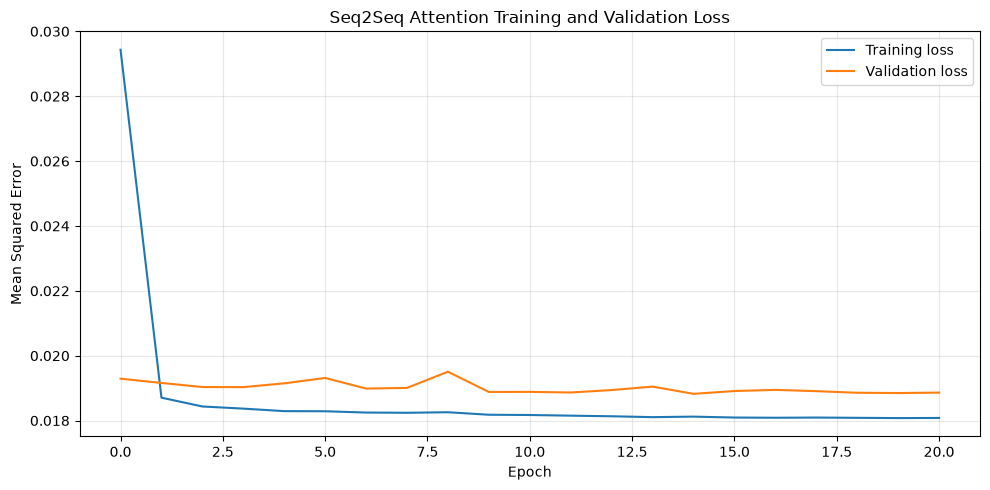

In [7]:

train_dataset = tf.data.Dataset.from_tensor_slices(
    ((x_train_encoder, x_train_decoder), y_train)
)
train_dataset = train_dataset.shuffle(
    len(x_train_encoder), seed=SEED
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

validation_dataset = tf.data.Dataset.from_tensor_slices(
    ((x_validation_encoder, x_validation_decoder), y_validation)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

history = seq2seq_model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

plt.figure(figsize=(10, 5))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Seq2Seq Attention Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(REPORT_DIR / "training_loss.png", dpi=150)
plt.show()


In [8]:

def predict_seq2seq_autoregressive(model, encoder_values, horizon, scale_min, scale_range):
    decoder_values = np.zeros((len(encoder_values), horizon, 1), dtype=np.float32)
    decoder_values[:, 0, 0] = encoder_values[:, -1, 0]
    predictions_actual = np.zeros((len(encoder_values), horizon), dtype=np.float32)

    for step in range(horizon):
        scaled_output = model.predict(
            [encoder_values, decoder_values], verbose=0
        )[:, step, 0]
        actual_output = np.maximum(0.0, scaled_output * scale_range + scale_min)
        predictions_actual[:, step] = actual_output

        if step + 1 < horizon:
            decoder_values[:, step + 1, 0] = (actual_output - scale_min) / scale_range

    return predictions_actual, decoder_values


def predict_single_step_lstm_recursively(model, encoder_values, horizon, scale_min, scale_range):
    rolling_windows = encoder_values.copy().astype(np.float32)
    predictions_actual = np.zeros((len(encoder_values), horizon), dtype=np.float32)

    for step in range(horizon):
        next_scaled = model.predict(rolling_windows, verbose=0).reshape(-1)
        next_actual = np.maximum(0.0, next_scaled * scale_range + scale_min)
        predictions_actual[:, step] = next_actual
        next_scaled = (next_actual - scale_min) / scale_range
        rolling_windows = np.concatenate(
            [rolling_windows[:, 1:, :], next_scaled.reshape(-1, 1, 1)],
            axis=1
        )

    return predictions_actual


def calculate_metrics(actual, predicted):
    actual_values = np.asarray(actual, dtype=np.float64).reshape(-1)
    predicted_values = np.asarray(predicted, dtype=np.float64).reshape(-1)
    errors = actual_values - predicted_values
    mae_value = float(np.mean(np.abs(errors)))
    rmse_value = float(np.sqrt(np.mean(errors ** 2)))
    non_zero = actual_values != 0
    mape_value = (
        float(np.mean(np.abs(errors[non_zero] / actual_values[non_zero])) * 100)
        if np.any(non_zero) else float("nan")
    )
    return mae_value, rmse_value, mape_value


seq2seq_test_predictions, test_decoder_inputs_for_attention = predict_seq2seq_autoregressive(
    seq2seq_model, x_test_encoder, FORECAST_HORIZON, scale_min, scale_range
)
y_test_actual = y_test[:, :, 0] * scale_range + scale_min

print("Multi-step predictions:", seq2seq_test_predictions.shape)
print("Actual targets:", y_test_actual.shape)


Multi-step predictions: (261, 14)
Actual targets: (261, 14)


In [9]:

comparison_rows = []
day9_model = None
day9_available = False
day9_message = "Day 9 model was not found. Train Day 9 to enable the comparison."

if DAY9_MODEL_PATH.is_file() and DAY9_METADATA_PATH.is_file():
    with DAY9_METADATA_PATH.open("r", encoding="utf-8") as file:
        day9_metadata = json.load(file)

    compatible = (
        int(day9_metadata.get("store_id", -1)) == STORE_ID
        and int(day9_metadata.get("item_id", -1)) == ITEM_ID
        and int(day9_metadata.get("look_back", -1)) == LOOK_BACK
        and np.isclose(float(day9_metadata.get("scale_min", np.nan)), scale_min)
        and np.isclose(float(day9_metadata.get("scale_max", np.nan)), scale_max)
    )

    if compatible:
        day9_model = tf.keras.models.load_model(DAY9_MODEL_PATH, compile=False)
        day9_available = True
        day9_message = "Day 9 single-step LSTM loaded successfully."
    else:
        day9_message = (
            "Day 9 model settings do not match Day 10. Retrain Day 9 with the same "
            "store, item, look-back window, and dataset split for a fair comparison."
        )

print(day9_message)

if day9_available:
    day9_test_predictions = predict_single_step_lstm_recursively(
        day9_model, x_test_encoder, FORECAST_HORIZON, scale_min, scale_range
    )
    model_predictions = [
        ("Day 9 single-step LSTM (recursive)", day9_test_predictions),
        ("Day 10 Seq2Seq + Attention", seq2seq_test_predictions)
    ]
else:
    model_predictions = [("Day 10 Seq2Seq + Attention", seq2seq_test_predictions)]

for model_name, predictions in model_predictions:
    for horizon_day in [1, 7, FORECAST_HORIZON]:
        mae_value, rmse_value, mape_value = calculate_metrics(
            y_test_actual[:, :horizon_day],
            predictions[:, :horizon_day]
        )
        comparison_rows.append({
            "model": model_name,
            "forecast_horizon_days": horizon_day,
            "mae": mae_value,
            "rmse": rmse_value,
            "mape": mape_value if np.isfinite(mape_value) else None
        })

comparison_table = pd.DataFrame(comparison_rows)
comparison_table.to_csv(REPORT_DIR / "model_comparison.csv", index=False)
print(comparison_table.to_string(index=False))


Day 9 single-step LSTM loaded successfully.
                             model  forecast_horizon_days      mae     rmse      mape
Day 9 single-step LSTM (recursive)                      1 4.873694 6.192201 21.757832
Day 9 single-step LSTM (recursive)                      7 4.932512 6.252841 22.557040
Day 9 single-step LSTM (recursive)                     14 5.064822 6.401162 23.227266
        Day 10 Seq2Seq + Attention                      1 4.774579 6.068796 21.927030
        Day 10 Seq2Seq + Attention                      7 4.864102 6.163387 22.800887
        Day 10 Seq2Seq + Attention                     14 4.954734 6.269899 23.491530


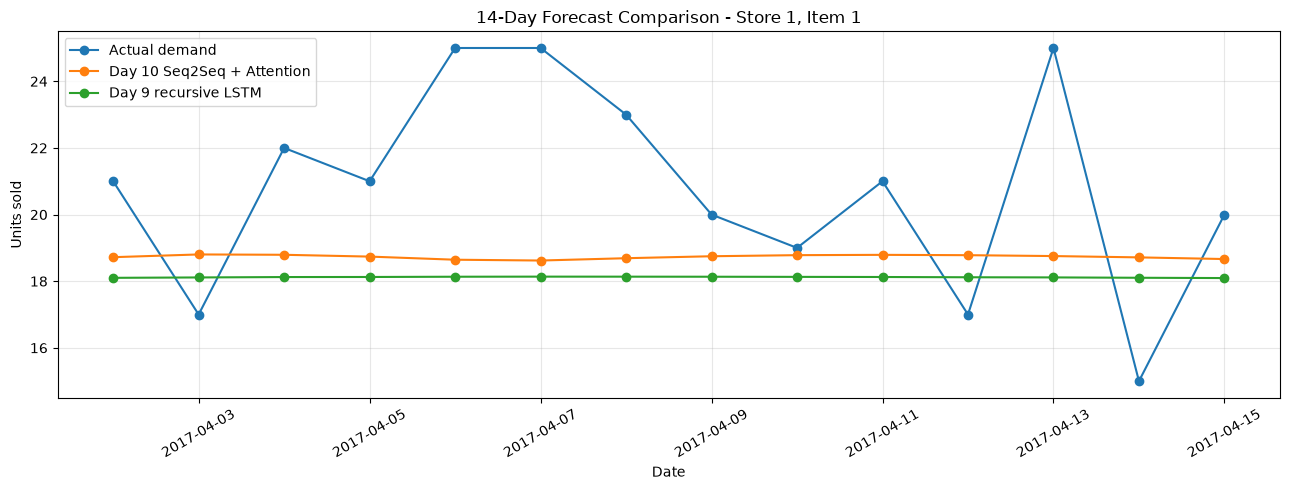

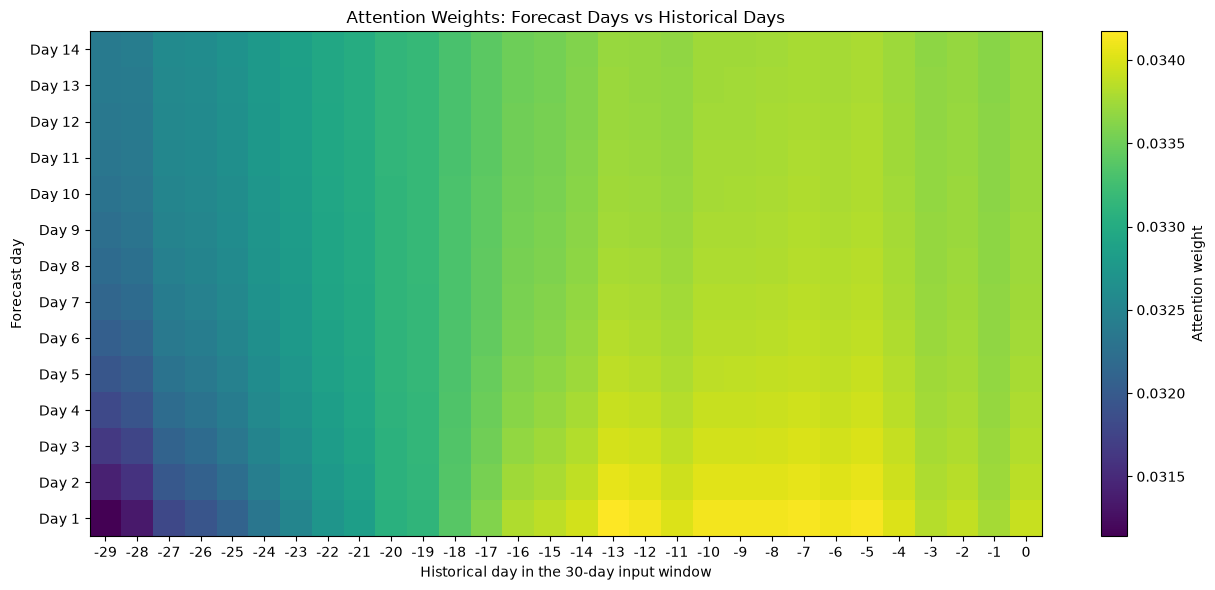

In [10]:

selected_index = 0
selected_origin = int(test_origins[selected_index])
selected_dates = daily_sales.index[
    selected_origin:selected_origin + FORECAST_HORIZON
]

plt.figure(figsize=(13, 5))
plt.plot(selected_dates, y_test_actual[selected_index], marker="o", label="Actual demand")
plt.plot(
    selected_dates,
    seq2seq_test_predictions[selected_index],
    marker="o",
    label="Day 10 Seq2Seq + Attention"
)
if day9_available:
    plt.plot(
        selected_dates,
        day9_test_predictions[selected_index],
        marker="o",
        label="Day 9 recursive LSTM"
    )
plt.title(f"{FORECAST_HORIZON}-Day Forecast Comparison - Store {STORE_ID}, Item {ITEM_ID}")
plt.xlabel("Date")
plt.ylabel("Units sold")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(REPORT_DIR / "multi_step_forecast_comparison.png", dpi=150)
plt.show()

selected_attention = attention_model.predict(
    [
        x_test_encoder[selected_index:selected_index + 1],
        test_decoder_inputs_for_attention[selected_index:selected_index + 1]
    ],
    verbose=0
)[0]

plt.figure(figsize=(13, 6))
plt.imshow(selected_attention, aspect="auto", origin="lower", cmap="viridis")
plt.colorbar(label="Attention weight")
plt.title("Attention Weights: Forecast Days vs Historical Days")
plt.xlabel("Historical day in the 30-day input window")
plt.ylabel("Forecast day")
plt.xticks(np.arange(LOOK_BACK), [str(i - LOOK_BACK + 1) for i in range(LOOK_BACK)])
plt.yticks(
    np.arange(FORECAST_HORIZON),
    [f"Day {i + 1}" for i in range(FORECAST_HORIZON)]
)
plt.tight_layout()
plt.savefig(REPORT_DIR / "attention_weights.png", dpi=150)
plt.show()


In [11]:

future_encoder = scaled_sales[-LOOK_BACK:].reshape(1, LOOK_BACK, 1).astype(np.float32)
future_predictions, future_decoder_inputs = predict_seq2seq_autoregressive(
    seq2seq_model, future_encoder, FORECAST_HORIZON, scale_min, scale_range
)

future_dates = pd.date_range(
    start=daily_sales.index[-1] + pd.Timedelta(days=1),
    periods=FORECAST_HORIZON,
    freq="D"
)
future_forecast = pd.DataFrame({
    "date": future_dates,
    "store": STORE_ID,
    "item": ITEM_ID,
    "forecast_sales": future_predictions[0]
})
future_forecast.to_csv(REPORT_DIR / "multi_week_demand_forecast.csv", index=False)
print(future_forecast.to_string(index=False))
print("Saved forecast:", REPORT_DIR / "multi_week_demand_forecast.csv")


      date  store  item  forecast_sales
2018-01-01      1     1       17.132324
2018-01-02      1     1       17.406559
2018-01-03      1     1       17.523911
2018-01-04      1     1       17.587135
2018-01-05      1     1       17.578054
2018-01-06      1     1       17.600979
2018-01-07      1     1       17.670843
2018-01-08      1     1       17.759514
2018-01-09      1     1       17.815231
2018-01-10      1     1       17.842682
2018-01-11      1     1       17.846407
2018-01-12      1     1       17.830566
2018-01-13      1     1       17.798859
2018-01-14      1     1       17.754539
Saved forecast: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\reports\day10_seq2seq_attention\multi_week_demand_forecast.csv


In [12]:

seq2seq_model.save(MODEL_PATH)

metadata = {
    "store_id": STORE_ID,
    "item_id": ITEM_ID,
    "look_back": LOOK_BACK,
    "forecast_horizon": FORECAST_HORIZON,
    "scale_min": scale_min,
    "scale_max": scale_max,
    "last_date": str(daily_sales.index[-1].date()),
    "last_window_scaled": scaled_sales[-LOOK_BACK:].astype(float).tolist(),
    "dataset": "Store Item Demand Forecasting Challenge",
    "target_column": "sales",
    "architecture": "LSTM encoder-decoder with temporal attention"
}
with METADATA_PATH.open("w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=4)

day10_metrics = {}
for horizon_day in [1, 7, FORECAST_HORIZON]:
    mae_value, rmse_value, mape_value = calculate_metrics(
        y_test_actual[:, :horizon_day],
        seq2seq_test_predictions[:, :horizon_day]
    )
    day10_metrics[str(horizon_day)] = {
        "mae": mae_value,
        "rmse": rmse_value,
        "mape": mape_value if np.isfinite(mape_value) else None
    }

with (REPORT_DIR / "metrics.json").open("w", encoding="utf-8") as file:
    json.dump(day10_metrics, file, indent=4)

print("Saved model:", MODEL_PATH)
print("Saved metadata:", METADATA_PATH)
print("Saved metrics:", REPORT_DIR / "metrics.json")


Saved model: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\models\forecasting\retailmind_seq2seq_attention.keras
Saved metadata: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\models\forecasting\retailmind_seq2seq_metadata.json
Saved metrics: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\reports\day10_seq2seq_attention\metrics.json


In [13]:

module_source = r"""
from pathlib import Path
import json
import numpy as np
import pandas as pd
import tensorflow as tf


def _find_project_dir():
    current_dir = Path.cwd().resolve()
    return next(
        (folder for folder in [current_dir, *current_dir.parents]
         if (folder / "models" / "forecasting").is_dir()),
        current_dir.parent if current_dir.name == "src" else current_dir
    )


def forecast_demand(steps=None, project_dir=None, save_csv=True):
    root = Path(project_dir).resolve() if project_dir else _find_project_dir()
    model_dir = root / "models" / "forecasting"
    model_path = model_dir / "retailmind_seq2seq_attention.keras"
    metadata_path = model_dir / "retailmind_seq2seq_metadata.json"

    if not model_path.is_file():
        raise FileNotFoundError(f"Trained Seq2Seq model not found: {model_path}")
    if not metadata_path.is_file():
        raise FileNotFoundError(f"Model metadata not found: {metadata_path}")

    with metadata_path.open("r", encoding="utf-8") as file:
        metadata = json.load(file)

    horizon = int(metadata["forecast_horizon"])
    if steps is None:
        steps = horizon
    if int(steps) != horizon:
        raise ValueError(
            f"This model was trained for {horizon} steps. "
            f"Use steps={horizon} or train a model with a different horizon."
        )

    model = tf.keras.models.load_model(model_path, compile=False)
    look_back = int(metadata["look_back"])
    window = np.asarray(
        metadata["last_window_scaled"], dtype=np.float32
    ).reshape(1, look_back, 1)

    scale_min = float(metadata["scale_min"])
    scale_range = float(metadata["scale_max"]) - scale_min
    if scale_range == 0:
        scale_range = 1.0

    decoder = np.zeros((1, horizon, 1), dtype=np.float32)
    decoder[:, 0, 0] = window[:, -1, 0]
    predictions = []

    for step in range(horizon):
        output = model.predict([window, decoder], verbose=0)
        scaled_value = float(output[0, step, 0])
        actual_value = max(0.0, scaled_value * scale_range + scale_min)
        predictions.append(actual_value)
        if step + 1 < horizon:
            decoder[0, step + 1, 0] = (actual_value - scale_min) / scale_range

    start_date = pd.Timestamp(metadata["last_date"]) + pd.Timedelta(days=1)
    dates = pd.date_range(start=start_date, periods=horizon, freq="D")
    result = pd.DataFrame({
        "date": dates,
        "store": metadata["store_id"],
        "item": metadata["item_id"],
        "forecast_sales": predictions
    })

    if save_csv:
        report_dir = root / "reports" / "day10_seq2seq_attention"
        report_dir.mkdir(parents=True, exist_ok=True)
        result.to_csv(report_dir / "multi_week_demand_forecast.csv", index=False)

    return result
"""

MODULE_PATH = SRC_DIR / "demand_forecaster.py"
MODULE_PATH.write_text(module_source, encoding="utf-8")
print("Updated forecasting module:", MODULE_PATH)

import importlib
import sys

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import demand_forecaster
importlib.reload(demand_forecaster)

module_forecast = demand_forecaster.forecast_demand(
    steps=FORECAST_HORIZON,
    project_dir=PROJECT_DIR,
    save_csv=True
)
print(module_forecast.to_string(index=False))


Updated forecasting module: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\src\demand_forecaster.py
      date  store  item  forecast_sales
2018-01-01      1     1       17.132324
2018-01-02      1     1       17.406559
2018-01-03      1     1       17.523911
2018-01-04      1     1       17.587135
2018-01-05      1     1       17.578054
2018-01-06      1     1       17.600980
2018-01-07      1     1       17.670843
2018-01-08      1     1       17.759514
2018-01-09      1     1       17.815232
2018-01-10      1     1       17.842682
2018-01-11      1     1       17.846408
2018-01-12      1     1       17.830565
2018-01-13      1     1       17.798858
2018-01-14      1     1       17.754540


In [14]:

README_PATH = PROJECT_DIR / "README.md"
full_mae, full_rmse, full_mape = calculate_metrics(
    y_test_actual, seq2seq_test_predictions
)
mape_text = f"{full_mape:.2f}%" if np.isfinite(full_mape) else "not available"

readme_section = (
    "## Day 10 - Seq2Seq and Attention Demand Forecasting\n\n"
    "Day 10 extended RetailMind AI demand forecasting from next-day prediction to multi-step forecasting "
    "using an LSTM encoder-decoder architecture with an attention mechanism. The Store Item Demand "
    "Forecasting dataset was reused with the selected store and product series from Day 9.\n\n"
    f"A {LOOK_BACK}-day historical window was encoded and the model generated a "
    f"{FORECAST_HORIZON}-day forecast. The encoder-decoder model used teacher forcing during training "
    "and autoregressive prediction during inference. A temporal attention layer assigned weights to "
    "historical encoder states for each forecast step.\n\n"
    f"On held-out test windows, the Day 10 model achieved MAE {full_mae:.3f}, "
    f"RMSE {full_rmse:.3f}, and MAPE {mape_text} across the full forecast horizon. "
)

if day9_available:
    baseline_mae, baseline_rmse, baseline_mape = calculate_metrics(
        y_test_actual, day9_test_predictions
    )
    baseline_mape_text = (
        f"{baseline_mape:.2f}%" if np.isfinite(baseline_mape) else "not available"
    )
    readme_section += (
        f"The Day 9 single-step LSTM, recursively applied over the same test windows, achieved "
        f"MAE {baseline_mae:.3f}, RMSE {baseline_rmse:.3f}, and MAPE {baseline_mape_text}. "
        "Detailed horizon-wise results are saved in the Day 10 reports.\n\n"
    )
else:
    readme_section += (
        "The Day 9 comparison was not available during this run because a compatible trained Day 9 model "
        "was not found. Train Day 9 with the same store, item, look-back window, and data split to complete "
        "the comparison.\n\n"
    )

readme_section += (
    "Attention weights were visualized to inspect which historical days influenced each forecast step. "
    "The reusable `src/demand_forecaster.py` module was upgraded to load the Seq2Seq attention model and "
    "generate multi-week forecasts for procurement and inventory planning.\n\n"
    "- Model: `models/forecasting/retailmind_seq2seq_attention.keras`\n"
    "- Metadata: `models/forecasting/retailmind_seq2seq_metadata.json`\n"
    "- Forecast module: `src/demand_forecaster.py`\n"
    "- Forecast output: `reports/day10_seq2seq_attention/multi_week_demand_forecast.csv`\n"
    "- Attention visualization: `reports/day10_seq2seq_attention/attention_weights.png`\n"
    "- Evaluation reports: `reports/day10_seq2seq_attention/`\n"
)

if README_PATH.is_file():
    readme_text = README_PATH.read_text(encoding="utf-8")
else:
    readme_text = "# RetailMind AI\n\n"

day10_heading = "## Day 10 - Seq2Seq and Attention Demand Forecasting"
if day10_heading not in readme_text:
    README_PATH.write_text(
        readme_text.rstrip() + "\n\n---\n\n" + readme_section,
        encoding="utf-8"
    )
    print("Day 10 section added to README.md")
else:
    print("Day 10 heading already exists. Update its results with the metrics above.")

print("Day 10 completed.")
print("Model:", MODEL_PATH)
print("Updated module:", MODULE_PATH)
print("Forecast:", REPORT_DIR / "multi_week_demand_forecast.csv")


Day 10 section added to README.md
Day 10 completed.
Model: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\models\forecasting\retailmind_seq2seq_attention.keras
Updated module: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\src\demand_forecaster.py
Forecast: C:\Users\rupam\OneDrive\Desktop\Retail_Mind\reports\day10_seq2seq_attention\multi_week_demand_forecast.csv
